# Taller 10 — Redes Neuronales Artificiales: clasificación de dígitos


In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             log_loss, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from IPython.display import display

SEMILLA = 42
ACTIVACIONES = ['identity', 'logistic', 'tanh', 'relu']
pd.set_option('display.max_columns', 20)
print('scikit-learn:', sklearn.__version__, '| numpy:', np.__version__, '| pandas:', pd.__version__)

scikit-learn: 1.6.1 | numpy: 2.1.3 | pandas: 2.2.3


## 1. Dataset `digits`
load_digits contiene 1.797 muestras de imágenes de 8 × 8 píxeles (64 intensidades por muestra, con valores entre 0 y 16). La etiqueta es uno de los dígitos 0 a 9. La red utiliza el vector aplanado de 64 características. Se visualizan muestras para verificar qué se clasifica.

Dimensión X: (1797, 64) | Dimensión y: (1797,)
Distribución de clases:


,Dígito,Cantidad
0,0,178
1,1,182
2,2,177
3,3,183
4,4,181
5,5,182
6,6,181
7,7,179
8,8,174
9,9,180


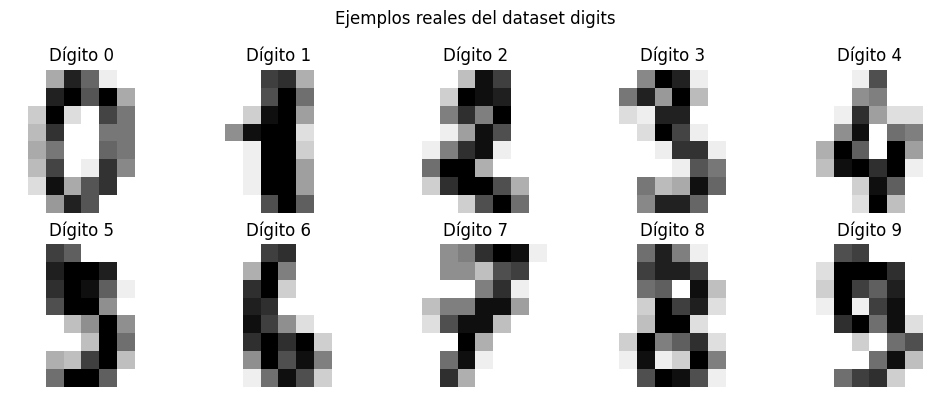

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
etiquetas = np.arange(10)
print('Dimensión X:', X.shape, '| Dimensión y:', y.shape)
print('Distribución de clases:')
display(pd.DataFrame({'Dígito': etiquetas, 'Cantidad': np.bincount(y, minlength=10)}))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digito, ax in enumerate(axes.flat):
    ix = np.flatnonzero(y == digito)[0]
    ax.imshow(digits.images[ix], cmap='gray_r', interpolation='nearest')
    ax.set_title(f'Dígito {digito}')
    ax.axis('off')
plt.suptitle('Ejemplos reales del dataset digits')
plt.tight_layout()
plt.show()

## 2. División de datos y control de fuga de información
Se utiliza 60 % entrenamiento, 20 % validación y 20 % prueba, como en la metodología del ejemplo. Las divisiones son estratificadas para conservar las proporciones de los diez dígitos. El StandardScaler se ajusta solo con entrenamiento, dentro de cada Pipeline. El conjunto de prueba se reserva hasta haber elegido la activación.

In [3]:
indices = np.arange(len(y))
idx_dev, idx_test = train_test_split(indices, test_size=0.20, random_state=SEMILLA, stratify=y)
idx_train, idx_val = train_test_split(idx_dev, test_size=0.25, random_state=SEMILLA, stratify=y[idx_dev])
X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))
assert len(set(idx_train) | set(idx_val) | set(idx_test)) == len(y)
display(pd.DataFrame([{'Partición': nombre, 'Muestras':len(z), 'Porcentaje':f'{len(z)/len(y):.1%}'}
                      for nombre,z in [('Entrenamiento',y_train),('Validación',y_val),('Prueba',y_test)]]))

,Partición,Muestras,Porcentaje
0,Entrenamiento,1077,59.9%
1,Validación,360,20.0%
2,Prueba,360,20.0%


## 3. Arquitectura y funciones de activación

La red neuronal utilizada tiene 64 entradas, una capa oculta con 64 neuronas y 10 salidas, correspondientes a las clases que se quieren predecir. Para comparar el comportamiento de la red, se probaron cuatro funciones de activación en la capa oculta: *identity*, *logistic*, *tanh* y *relu*. En la capa de salida se utiliza *softmax*, que permite obtener una probabilidad para cada clase.

| Activación | Expresión | Descripción |
|---|---|---|
| identity | \(f(z)=z\) | Devuelve el mismo valor de entrada, por lo que no introduce cambios no lineales en los datos. |
| logistic | \(f(z)=1/(1+e^{-z})\) | Es una función sigmoide que transforma los valores a un rango entre 0 y 1. Cuando los valores son muy altos o bajos, el aprendizaje puede volverse más lento. |
| tanh | \(f(z)=\tanh(z)\) | Produce valores entre -1 y 1 y está centrada en cero. Al igual que la sigmoide, puede dificultar el aprendizaje cuando sus valores se saturan. |
| relu | \(f(z)=\max(0,z)\) | Convierte los valores negativos en cero y mantiene los positivos. Permite que la red aprenda relaciones no lineales, aunque algunas neuronas pueden dejar de activarse durante el entrenamiento. |

Para realizar las pruebas se utilizaron los parámetros solver='lbfgs', alpha=1e-4, max_iter=2000, max_fun=50000 y tol=1e-6, con una semilla aleatoria de 42. Estos valores se mantuvieron iguales en todos los experimentos para que la comparación se centrara en la función de activación utilizada.

El tiempo de ejecución se midió con perf_counter(). Este tiempo puede variar dependiendo del equipo en el que se ejecute el programa. Además, max_iter establece el número máximo de iteraciones permitidas, por lo que la red puede terminar el entrenamiento antes de alcanzar ese límite.

### 3.1. Comportamiento visual de las funciones de activación

Las curvas ilustran sus rangos y no linealidades. identity es lineal. logistic se acerca a 0 y 1. tanh se aproxima a −1 y 1. relu es cero para valores negativos y lineal para positivos.

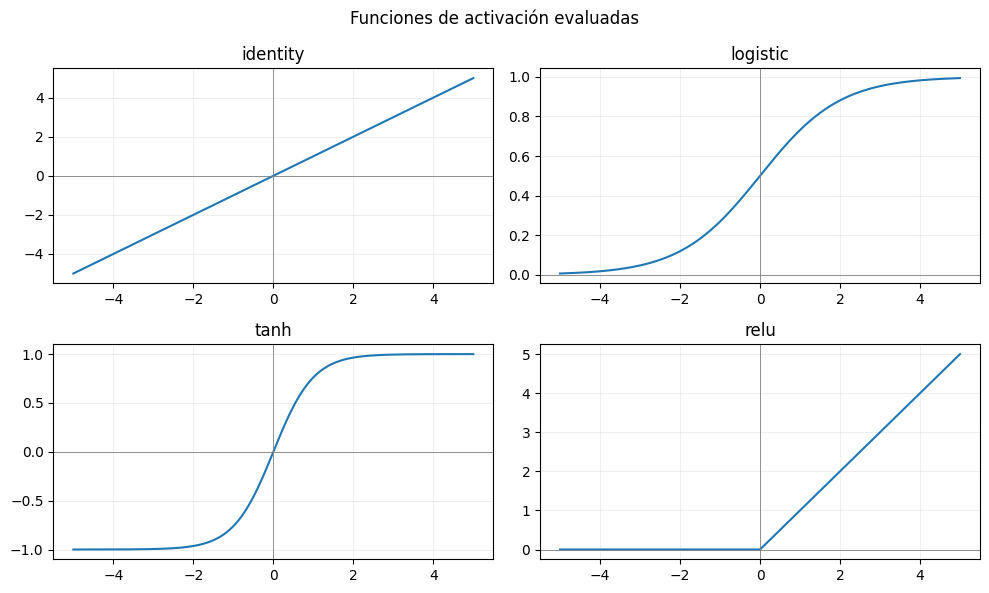

In [4]:
z = np.linspace(-5, 5, 400)
funciones = {'identity':z, 'logistic':1/(1+np.exp(-z)), 'tanh':np.tanh(z), 'relu':np.maximum(0,z)}
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (nombre, valores) in zip(axes.flat, funciones.items()):
    ax.plot(z, valores)
    ax.axhline(0, color='gray', linewidth=.6)
    ax.axvline(0, color='gray', linewidth=.6)
    ax.set_title(nombre)
    ax.grid(alpha=.2)
plt.suptitle('Funciones de activación evaluadas')
plt.tight_layout()
plt.show()

In [5]:
def construir_mlp(activacion, semilla=SEMILLA):
    return Pipeline([
        ('escala', StandardScaler()),
        ('mlp', MLPClassifier(hidden_layer_sizes=(64,), activation=activacion,
                              solver='lbfgs', alpha=1e-4, tol=1e-6,
                              max_iter=2000, max_fun=50000, random_state=semilla))
    ])

def evaluar(modelo, entradas, verdaderas):
    predichas = modelo.predict(entradas)
    probabilidades = modelo.predict_proba(entradas)
    return {
        'Accuracy': accuracy_score(verdaderas, predichas),
        'Balanced accuracy': balanced_accuracy_score(verdaderas, predichas),
        'F1 macro': f1_score(verdaderas, predichas, average='macro', zero_division=0),
        'Log loss': log_loss(verdaderas, probabilidades, labels=etiquetas)
    }

print('Arquitectura: 64 entradas, 64 neuronas ocultas y 10 salidas.')

Arquitectura: 64 entradas, 64 neuronas ocultas y 10 salidas.


## 4. Referencia sin aprendizaje de patrones
Se incluye un DummyClassifier(strategy='most_frequent'), que siempre predice la clase mayoritaria, para comprobar que una accuracy elevada no se produce solo por la distribución de etiquetas.

In [6]:
referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
print('Referencia en validación:')
display(pd.DataFrame([evaluar(referencia,X_val,y_val)],index=['Mayoritaria']).round(4))

Referencia en validación:


,Accuracy,Balanced accuracy,F1 macro,Log loss
Mayoritaria,0.1028,0.1,0.0186,32.3392


## 5. Entrenamiento y comparación en validación
Entrenamos cuatro MLP sobre exactamente los mismos datos. Registramos métricas de entrenamiento y validación, tiempo, iteraciones y advertencias. Accuracy es el porcentaje de aciertos. balanced accuracy promedia el recall por dígito. F1 macro promedia el F1 de las diez clases. log loss mide la calidad de las probabilidades.

In [7]:
modelos = {}
filas = []
avisos_por_modelo = {}
for activacion in ACTIVACIONES:
    modelo = construir_mlp(activacion)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        modelo.fit(X_train, y_train)
    duracion = time.perf_counter() - inicio
    mensajes = [str(a.message) for a in avisos if issubclass(a.category, ConvergenceWarning)]
    for a in avisos:
        if not issubclass(a.category, ConvergenceWarning):
            warnings.warn(str(a.message), a.category)
    train = evaluar(modelo, X_train, y_train)
    val = evaluar(modelo, X_val, y_val)
    filas.append({'Activación':activacion, 'Accuracy train':train['Accuracy'],
                  'Accuracy val':val['Accuracy'], 'Balanced accuracy val':val['Balanced accuracy'],
                  'F1 macro val':val['F1 macro'], 'Log loss val':val['Log loss'],
                  'Tiempo (s)':duracion, 'Iteraciones':modelo.named_steps['mlp'].n_iter_,
                  'Aviso convergencia':bool(mensajes)})
    modelos[activacion] = modelo
    avisos_por_modelo[activacion] = mensajes
    print(f'{activacion}: validación={val["Accuracy"]:.4f}, tiempo={duracion:.3f}s, avisos={len(mensajes)}')
resultados = pd.DataFrame(filas).set_index('Activación')
display(resultados.round(4))
for nombre, mensajes in avisos_por_modelo.items():
    for mensaje in mensajes:
        print(f'Advertencia [{nombre}]: {mensaje}')

identity: validación=0.9528, tiempo=1.655s, avisos=0
logistic: validación=0.9750, tiempo=1.352s, avisos=0
tanh: validación=0.9667, tiempo=0.777s, avisos=0
relu: validación=0.9611, tiempo=0.624s, avisos=0


,Accuracy train,Accuracy val,Balanced accuracy val,F1 macro val,Log loss val,Tiempo (s),Iteraciones,Aviso convergencia
Activación,,,,,,,,
identity,1.0,0.9528,0.9527,0.9525,0.5020,1.6552,24,False
logistic,1.0,0.9750,0.9750,0.9752,0.1042,1.3515,44,False
tanh,1.0,0.9667,0.9665,0.9667,0.1345,0.7768,19,False
relu,1.0,0.9611,0.9609,0.9611,0.1905,0.6236,23,False


## 6. Visualización y selección de activación
La regla de selección se fija antes de consultar la prueba: mayor balanced accuracy de validación. en caso de empate, menor log loss. luego menor tiempo de entrenamiento. Así se prioriza reconocer correctamente todas las clases y se utiliza el tiempo como criterio de eficiencia.

Los tiempos observados corresponden a una ejecución. Su comparación es orientativa, pues dependen del hardware, la carga del sistema y la convergencia. Un único experimento tampoco demuestra superioridad universal.

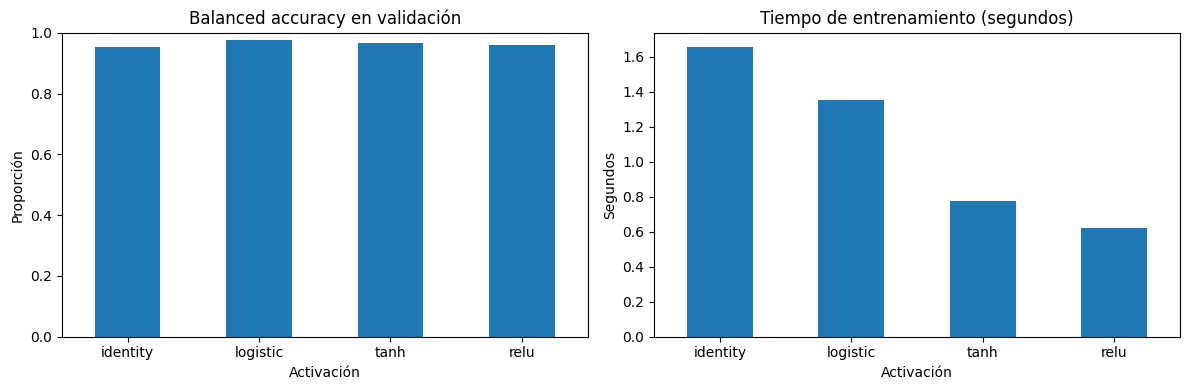

Mayor balanced accuracy: logistic
Entrenamiento más rápido: relu
La selección definitiva se calcula en la siguiente sección.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
resultados['Balanced accuracy val'].plot.bar(ax=axes[0], ylim=(0,1), title='Balanced accuracy en validación')
resultados['Tiempo (s)'].plot.bar(ax=axes[1], title='Tiempo de entrenamiento (segundos)')
axes[0].set_ylabel('Proporción')
axes[1].set_ylabel('Segundos')
for ax in axes:
    ax.set_xlabel('Activación')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()
# La selección definitiva se realiza después de revisar las cinco semillas.
mas_rapida = resultados['Tiempo (s)'].idxmin()
print('Mayor balanced accuracy:', resultados['Balanced accuracy val'].idxmax())
print('Entrenamiento más rápido:', mas_rapida)
print('La selección definitiva se calcula en la siguiente sección.')

### 6.1. Estabilidad con cinco inicializaciones

La comparación de una sola ejecución puede depender de la inicialización aleatoria. Repetimos cada activación con cinco semillas distintas sin alterar las particiones. la prueba queda reservada para la evaluación final. Se resumen media, desviación estándar, tiempo e iteraciones. Esta prueba no equivale a validación cruzada ni demuestra superioridad estadística general.

,accuracy_media,accuracy_desv,balanced_media,tiempo_medio,tiempo_desv,iteraciones_medias,advertencias
Activación,,,,,,,
identity,0.9517,0.0046,0.9515,0.5323,0.1451,23.6,0
logistic,0.9800,0.0050,0.9799,1.7715,0.5596,42.0,0
tanh,0.9728,0.0023,0.9726,1.5978,0.7910,20.4,0
relu,0.9689,0.0072,0.9687,0.7738,0.2228,22.2,0


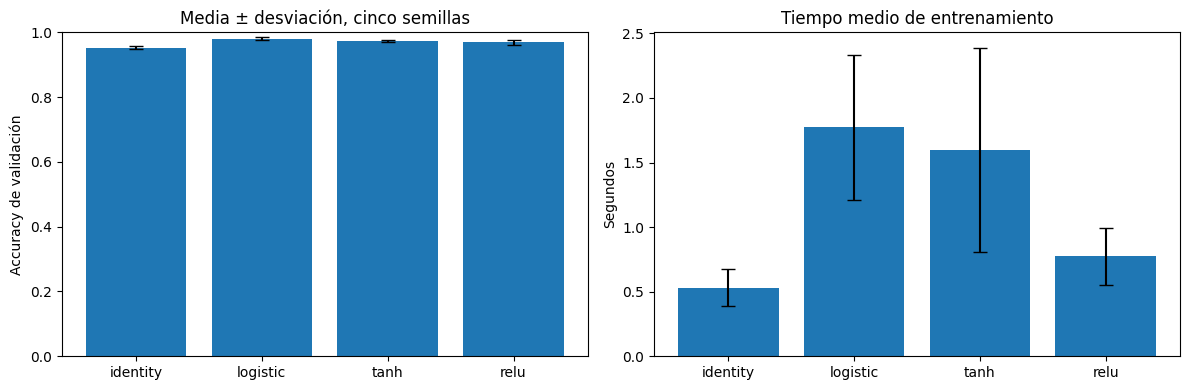

In [9]:
registros = []
for semilla in range(5):
    for activacion in ACTIVACIONES:
        modelo_rep = construir_mlp(activacion, semilla=semilla)
        inicio = time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter('always', ConvergenceWarning)
            modelo_rep.fit(X_train, y_train)
        tiempo = time.perf_counter() - inicio
        registros.append({'Activación': activacion, 'Semilla': semilla,
                          'Accuracy val': accuracy_score(y_val, modelo_rep.predict(X_val)),
                          'Balanced accuracy val':balanced_accuracy_score(y_val, modelo_rep.predict(X_val)),
                          'Tiempo (s)': tiempo, 'Iteraciones':modelo_rep.named_steps['mlp'].n_iter_,
                          'Advertencia':any(issubclass(a.category, ConvergenceWarning) for a in avisos)})
repeticiones = pd.DataFrame(registros)
estabilidad = repeticiones.groupby('Activación',sort=False).agg(
    accuracy_media=('Accuracy val','mean'), accuracy_desv=('Accuracy val','std'),
    balanced_media=('Balanced accuracy val','mean'),
    tiempo_medio=('Tiempo (s)','mean'), tiempo_desv=('Tiempo (s)','std'),
    iteraciones_medias=('Iteraciones','mean'), advertencias=('Advertencia','sum'))
display(estabilidad.round(4))
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(estabilidad.index, estabilidad['accuracy_media'],yerr=estabilidad['accuracy_desv'],capsize=5)
axes[0].set_ylim(0,1); axes[0].set_ylabel('Accuracy de validación')
axes[0].set_title('Media ± desviación, cinco semillas')
axes[1].bar(estabilidad.index,estabilidad['tiempo_medio'],yerr=estabilidad['tiempo_desv'],capsize=5)
axes[1].set_ylabel('Segundos');axes[1].set_title('Tiempo medio de entrenamiento')
plt.tight_layout();plt.show()

### 6.2. Selección transparente del modelo

Se elige la activación con mayor balanced accuracy media entre cinco semillas. En caso de empate, se prefiere menor desviación de accuracy y luego menor log loss en la corrida principal. Los tiempos se muestran y se consideran para interpretar la conveniencia práctica, como solicita el taller. Se utiliza el modelo de la ejecución principal (semilla 42) de la activación elegida, sin reentrenar sobre prueba.

In [10]:
ranking = (estabilidad.reset_index()
    .merge(resultados[['Log loss val']].reset_index(), on='Activación')
    .sort_values(['balanced_media','accuracy_desv','Log loss val','Activación'],
                 ascending=[False,True,True,True],kind='mergesort'))
display(ranking[['Activación','balanced_media','accuracy_desv','tiempo_medio','Log loss val']].round(4))
mejor_activacion = ranking.iloc[0]['Activación']
mejor_modelo = modelos[mejor_activacion]
print('Activación seleccionada:',mejor_activacion)
print('Advertencias de convergencia (semilla principal):',avisos_por_modelo[mejor_activacion])

,Activación,balanced_media,accuracy_desv,tiempo_medio,Log loss val
1,logistic,0.9799,0.0050,1.7715,0.1042
2,tanh,0.9726,0.0023,1.5978,0.1345
3,relu,0.9687,0.0072,0.7738,0.1905
0,identity,0.9515,0.0046,0.5323,0.5020


Activación seleccionada: logistic
Advertencias de convergencia (semilla principal): []


## 7. Evaluación final: conjunto de prueba
Se evalúa una sola vez la activación seleccionada con datos de prueba no utilizados para elegir hiperparámetros. Se reportan matriz de confusión y métricas por dígito. No se reajusta el modelo con validación para mantener independiente la prueba.

Resultados en prueba:


,Accuracy,Balanced accuracy,F1 macro,Log loss
Referencia,0.1000,0.1000,0.0182,32.4393
MLP (logistic),0.9611,0.9607,0.9602,0.1611


Clasificación detallada por dígito:
              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.9375    0.8333    0.8824        36
           2     0.9722    1.0000    0.9859        35
           3     1.0000    1.0000    1.0000        37
           4     0.9730    1.0000    0.9863        36
           5     0.9487    1.0000    0.9737        37
           6     1.0000    0.9722    0.9859        36
           7     0.9474    1.0000    0.9730        36
           8     0.9375    0.8571    0.8955        35
           9     0.8974    0.9722    0.9333        36

    accuracy                         0.9611       360
   macro avg     0.9614    0.9607    0.9602       360
weighted avg     0.9615    0.9611    0.9604       360



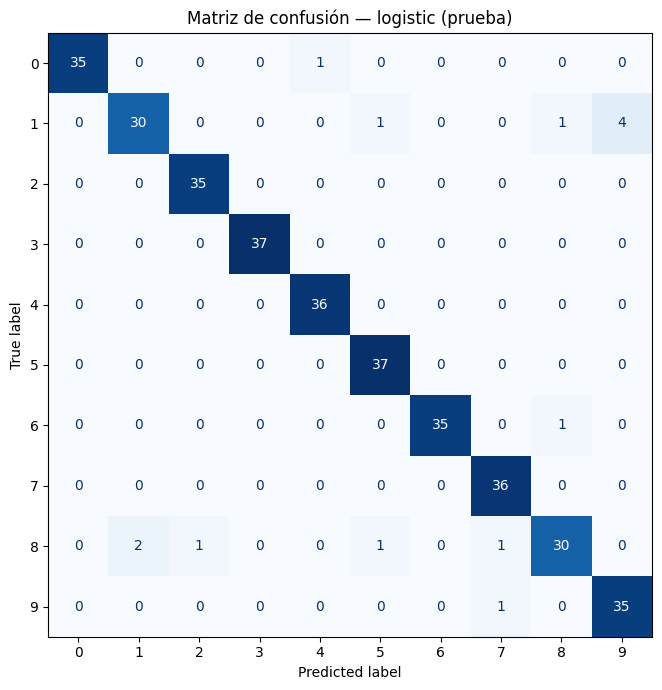

In [11]:
tabla_prueba = pd.DataFrame({
    'Referencia':evaluar(referencia,X_test,y_test),
    f'MLP ({mejor_activacion})':evaluar(mejor_modelo,X_test,y_test)
}).T
print('Resultados en prueba:')
display(tabla_prueba.round(4))
y_pred_test = mejor_modelo.predict(X_test)
print('Clasificación detallada por dígito:')
print(classification_report(y_test,y_pred_test,labels=etiquetas,digits=4,zero_division=0))
fig, ax=plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay(confusion_matrix(y_test,y_pred_test,labels=etiquetas),
                       display_labels=etiquetas).plot(ax=ax,cmap='Blues',values_format='d',colorbar=False)
ax.set_title(f'Matriz de confusión — {mejor_activacion} (prueba)')
plt.tight_layout()
plt.show()

## 8. Ejemplos de predicción
Se muestran diez imágenes de prueba con etiqueta real y predicción del modelo seleccionado. Los errores, si existen, se identifican en el título.

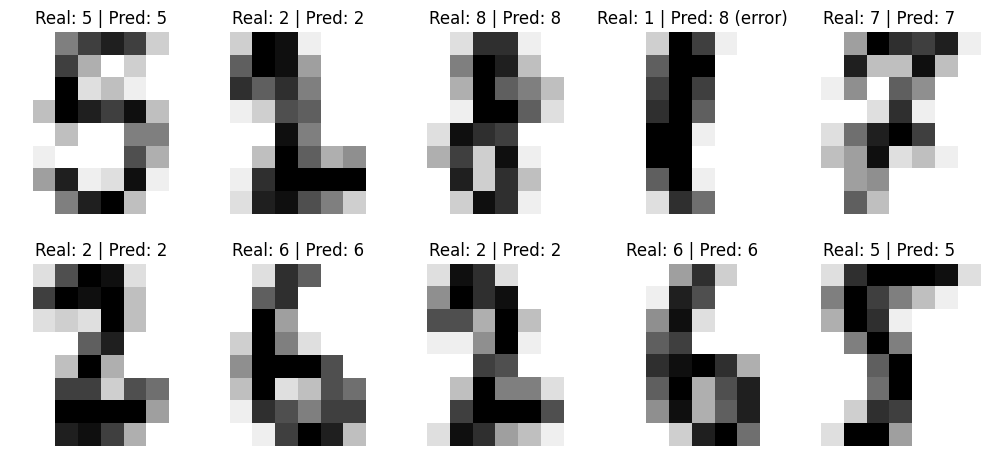

In [12]:
fig, axes=plt.subplots(2,5,figsize=(10,5))
for ax, indice in zip(axes.flat, range(10)):
    ax.imshow(X_test[indice].reshape(8,8),cmap='gray_r',interpolation='nearest')
    acierto=y_pred_test[indice]==y_test[indice]
    ax.set_title(f'Real: {y_test[indice]} | Pred: {y_pred_test[indice]}' + ('' if acierto else ' (error)'))
    ax.axis('off')
plt.tight_layout()
plt.show()

### 8.1. Análisis de errores

Inspeccionar las imágenes mal clasificadas ayuda a interpretar limitaciones del reconocimiento de dígitos en una resolución de 8 × 8.

Errores: 14 de 360 imágenes de prueba


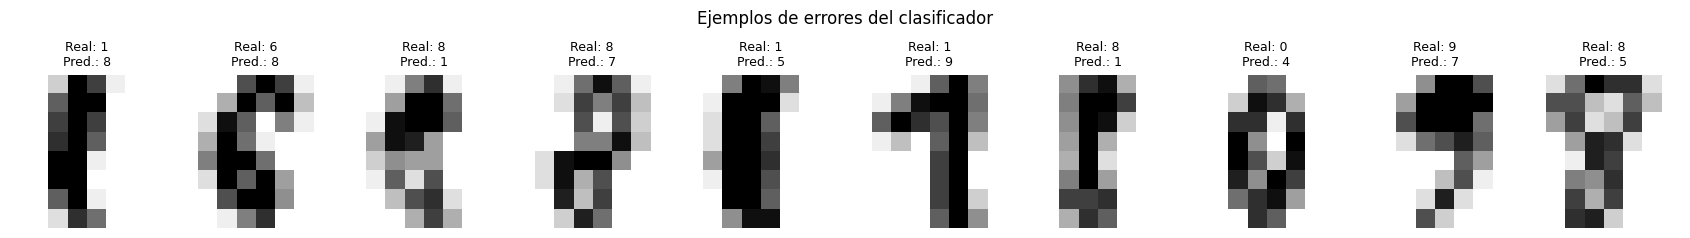

In [13]:
errores = np.flatnonzero(y_pred_test != y_test)
print(f'Errores: {len(errores)} de {len(y_test)} imágenes de prueba')
if len(errores):
    n = min(10,len(errores))
    fig, axes = plt.subplots(1,n,figsize=(1.7*n,2.6))
    for ax, i in zip(np.atleast_1d(axes),errores[:n]):
        ax.imshow(X_test[i].reshape(8,8),cmap='gray_r')
        ax.set_title(f'Real: {y_test[i]}\nPred.: {y_pred_test[i]}',fontsize=9)
        ax.axis('off')
    plt.suptitle('Ejemplos de errores del clasificador')
    plt.tight_layout();plt.show()

## 9. Análisis e interpretación de los resultados obtenidos
Las conclusiones que siguen se generan directamente de las métricas medidas en validación y prueba; de este modo, reflejan la ejecución del notebook y no resultados supuestos.

La comparación incluye ahora la variación de desempeño y duración entre inicializaciones y el número de iteraciones como indicios del costo y de la convergencia. La comparación de prueba no interviene en la selección.

In [14]:
mejor_exactitud = resultados['Accuracy val'].idxmax()
mayor_f1 = resultados['F1 macro val'].idxmax()
peor_balanceada = resultados['Balanced accuracy val'].idxmin()
val_sel = resultados.loc[mejor_activacion]
mejor_tiempo = resultados.loc[mas_rapida, 'Tiempo (s)']
print('ANÁLISIS POR ACTIVACIÓN')
for activacion in ACTIVACIONES:
    fila = resultados.loc[activacion]
    print(f'- {activacion}: accuracy={fila["Accuracy val"]:.2%}, '
          f'balanced accuracy={fila["Balanced accuracy val"]:.2%}, '
          f'F1 macro={fila["F1 macro val"]:.3f}, '
          f'log loss={fila["Log loss val"]:.3f}, '
          f'tiempo={fila["Tiempo (s)"]:.3f} s.')
print('\nINTERPRETACIÓN')
print(f'La mayor accuracy de validación fue de {mejor_exactitud} ({resultados.loc[mejor_exactitud,"Accuracy val"]:.2%}).')
print(f'El mayor F1 macro correspondió a {mayor_f1}; la menor balanced accuracy, a {peor_balanceada}.')
print(f'La función más rápida fue {mas_rapida} ({mejor_tiempo:.3f} s).')
print(f'Según el criterio establecido, conviene utilizar {mejor_activacion}: '
      f'balanced accuracy={val_sel["Balanced accuracy val"]:.2%}, '
      f'accuracy={val_sel["Accuracy val"]:.2%} y tiempo={val_sel["Tiempo (s)"]:.3f} s.')
print(f'Su exactitud en prueba fue {tabla_prueba.loc[f"MLP ({mejor_activacion})","Accuracy"]:.2%}.')
print('Diferencia entre exactitud entrenamiento/validación de la elegida: '
      f'{resultados.loc[mejor_activacion,"Accuracy train"]-val_sel["Accuracy val"]:+.3f}; '
      'una brecha positiva elevada sugeriría sobreajuste.')
if mas_rapida!=mejor_activacion:
    print('Hay un compromiso entre rendimiento y costo computacional: '
          f'{mas_rapida} entrena más rápido, pero la selección favorece el reconocimiento balanceado.')
else:
    print('La opción seleccionada también fue la más rápida en esta ejecución.')
if avisos_por_modelo[mejor_activacion]:
    print('ATENCIÓN: el modelo elegido generó advertencias de convergencia; '
          'conviene revisar la optimización antes de una conclusión definitiva.')
print('Estas conclusiones son válidas para el split, semilla y configuración evaluados.')

ANÁLISIS POR ACTIVACIÓN
- identity: accuracy=95.28%, balanced accuracy=95.27%, F1 macro=0.953, log loss=0.502, tiempo=1.655 s.
- logistic: accuracy=97.50%, balanced accuracy=97.50%, F1 macro=0.975, log loss=0.104, tiempo=1.352 s.
- tanh: accuracy=96.67%, balanced accuracy=96.65%, F1 macro=0.967, log loss=0.134, tiempo=0.777 s.
- relu: accuracy=96.11%, balanced accuracy=96.09%, F1 macro=0.961, log loss=0.190, tiempo=0.624 s.

INTERPRETACIÓN
La mayor accuracy de validación fue de logistic (97.50%).
El mayor F1 macro correspondió a logistic; la menor balanced accuracy, a identity.
La función más rápida fue relu (0.624 s).
Según el criterio establecido, conviene utilizar logistic: balanced accuracy=97.50%, accuracy=97.50% y tiempo=1.352 s.
Su exactitud en prueba fue 96.11%.
Diferencia entre exactitud entrenamiento/validación de la elegida: +0.025; una brecha positiva elevada sugeriría sobreajuste.
Hay un compromiso entre rendimiento y costo computacional: relu entrena más rápido, pero la s

## 10. Conclusión y entrega
Conclusión metodológica: las funciones identity, logistic, tanh y relu no son equivalentes. identity no introduce no linealidad; las otras tres permiten representaciones no lineales con distintos comportamientos de saturación y optimización. La elección concreta se basa en los resultados reproducidos arriba, considerando **precisión por clase y tiempo de entrenamiento**, no solo la accuracy.


